# ReturnRadar: E-Commerce Return Risk Prediction and Customer Behavior Analysis

## 1. Project Introduction

E-commerce businesses face challenges when customers return purchased products. Frequent product returns can increase operational costs, affect inventory management, and impact business performance.

ReturnRadar is a machine learning project designed to analyze customer purchasing behavior and predict whether an e-commerce order item is likely to be returned.

## Project Objectives

- Analyze e-commerce customer and order information.
- Identify patterns associated with product returns.
- Perform data cleaning and exploratory data analysis.
- Build machine learning classification models.
- Evaluate model performance using accuracy, precision, recall, F1-score, and ROC-AUC.
- Identify a suitable model for return prediction.

In [2]:

# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset

df = pd.read_csv("../data/BADS_WS2021_known.csv",na_values=["NA", "", "?"])

print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (100000, 14)


,order_item_id,order_date,delivery_date,item_id,item_size,item_color,brand_id,item_price,user_id,user_title,user_dob,user_state,user_reg_date,return
0,1,2016-06-22,2016-06-27,643,38,navy,30,49.90,30822,Mrs,1969-04-17,Saxony,2016-06-23,0
1,2,2016-06-22,NaN,337,152,grey,30,19.95,30822,Mrs,1969-04-17,Saxony,2016-06-23,0
2,3,2016-06-22,2016-06-27,270,xxl,grey,49,79.90,30823,Mrs,1970-04-22,Baden-Wuerttemberg,2015-03-15,1
3,4,2016-06-22,2016-06-27,142,xxl,grey,49,99.90,30823,Mrs,1970-04-22,Baden-Wuerttemberg,2015-03-15,0
4,5,2016-06-22,2016-06-27,561,xxl,grey,3,14.90,30823,Mrs,1970-04-22,Baden-Wuerttemberg,2015-03-15,1


## 2. Dataset Overview

In this step, we examine the dataset structure, column data types, and missing values to understand the quality of the data before preprocessing.

In [3]:
# Check dataset information

df.info()

# Check missing values in each column

print("\nMissing values in each column:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   order_item_id  100000 non-null  int64  
 1   order_date     100000 non-null  object 
 2   delivery_date  90682 non-null   object 
 3   item_id        100000 non-null  int64  
 4   item_size      100000 non-null  object 
 5   item_color     99939 non-null   object 
 6   brand_id       100000 non-null  int64  
 7   item_price     100000 non-null  float64
 8   user_id        100000 non-null  int64  
 9   user_title     100000 non-null  object 
 10  user_dob       91275 non-null   object 
 11  user_state     100000 non-null  object 
 12  user_reg_date  100000 non-null  object 
 13  return         100000 non-null  int64  
dtypes: float64(1), int64(5), object(8)
memory usage: 10.7+ MB

Missing values in each column:
order_item_id       0
order_date          0
delivery_date    9318
item_id  

## 3. Target Variable Distribution

The target variable is `return`.

- 0 represents an order item that was not returned.
- 1 represents an order item that was returned.

We examine the distribution to understand whether the dataset is balanced or imbalanced.

In [4]:
# Count returned and non-returned items

print(df['return'].value_counts())

# Calculate percentages

print("\nTarget variable percentages:")
print(df['return'].value_counts(normalize=True) * 100)

return
0    54182
1    45818
Name: count, dtype: int64

Target variable percentages:
return
0    54.182
1    45.818
Name: proportion, dtype: float64


### 3.1 Target Variable Distribution

This chart shows the distribution of returned and non-returned order items.

**Insight:** The dataset contains 54.18% non-returned items and 45.82% returned items. The classes are relatively balanced, so severe class imbalance is not a major concern.

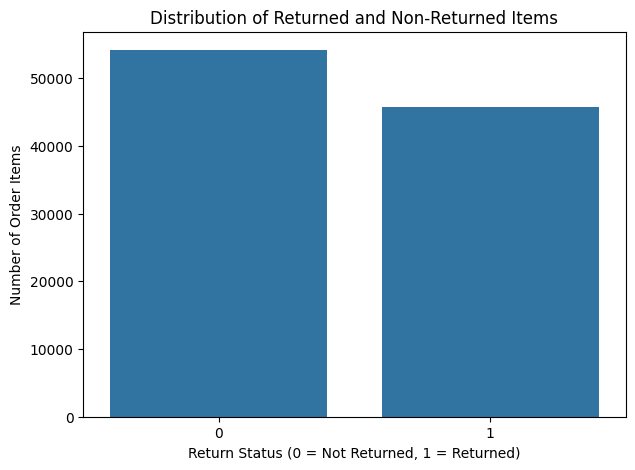

In [5]:
# Visualize target variable distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='return')

plt.title('Distribution of Returned and Non-Returned Items')
plt.xlabel('Return Status (0 = Not Returned, 1 = Returned)')
plt.ylabel('Number of Order Items')

plt.show()